In [1]:
%pip install -q kagglehub apyori

Note: you may need to restart the kernel to use updated packages.


In [11]:
import glob
import os
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
from apyori import apriori

In [4]:
path = kagglehub.dataset_download("hemanthkumar05/market-basket-optimization")
print(glob.glob(path+"/*"))
df=pd.read_csv(os.path.join(path,"Market_Basket_Optimisation.csv"))

['/Users/siyasinnarkar/.cache/kagglehub/datasets/hemanthkumar05/market-basket-optimization/versions/1/Market_Basket_Optimisation.csv']


In [5]:
transactions=[[str(x) for x in row if str(x)!='nan'] for row in df.values]

In [8]:
rules=list(apriori(transactions,min_support=0.003,min_confidence=0.02,min_lift=3,min_length=2))
print("Number of rules: ",len(rules))

Number of rules:  94


In [9]:
rows = []
for r in rules:
    for s in r.ordered_statistics:
        rows.append([", ".join(s.items_base), ", ".join(s.items_add),
                     r.support, s.confidence, s.lift])
rules_df = pd.DataFrame(rows, columns=["If bought", "Then buys", "Support", "Confidence", "Lift"])
rules_df = rules_df.sort_values("Confidence", ascending=False).reset_index(drop=True)
print(rules_df.head(10))


                                   If bought      Then buys   Support  \
0              frozen vegetables, soup, milk  mineral water  0.003067   
1                       ground beef, cereals      spaghetti  0.003067   
2                        tomatoes, olive oil      spaghetti  0.004400   
3     frozen vegetables, soup, mineral water           milk  0.003067   
4                  ground beef, tomato sauce      spaghetti  0.003067   
5                   ground beef, cooking oil      spaghetti  0.004800   
6       ground beef, tomatoes, mineral water      spaghetti  0.003067   
7       frozen vegetables, milk, ground beef      spaghetti  0.003067   
8  chocolate, ground beef, frozen vegetables      spaghetti  0.003067   
9                             red wine, eggs      spaghetti  0.003733   

   Confidence      Lift  
0    0.766667  3.217683  
1    0.676471  3.884785  
2    0.611111  3.509444  
3    0.605263  4.670240  
4    0.575000  3.302067  
5    0.571429  3.281558  
6    0.560976 

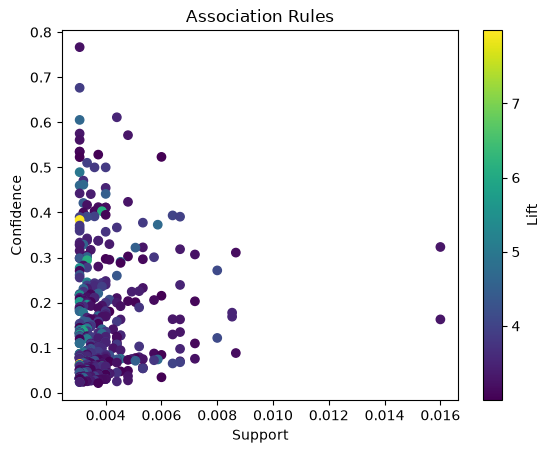

In [12]:
plt.scatter(rules_df["Support"], rules_df["Confidence"], c=rules_df["Lift"], cmap="viridis")
plt.colorbar(label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules")
plt.show()

In [13]:
for conf in [0.3, 0.4, 0.5, 0.6, 0.7]:
    n = len(list(apriori(transactions, min_support=0.003, min_confidence=conf,
                         min_lift=3, min_length=2)))
    print("Min confidence", conf, "-> rules:", n)

Min confidence 0.3 -> rules: 51
Min confidence 0.4 -> rules: 31
Min confidence 0.5 -> rules: 14
Min confidence 0.6 -> rules: 3
Min confidence 0.7 -> rules: 1
